# How are in-demand skills trending for Data Engineers

## Steps
1. Aggregate monthly skill counts
2. Analyse based on percentage of total jobs
3. Plot the in-demand skill counts 

In [ ]:
#Import Libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

#Load Dataset
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#Data Clean
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

/opt/anaconda3/envs/python_project/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
df_de_usa = df[(df['job_title_short'] == 'Data Engineer') & (df['job_country'] == 'United States')].copy()

df_de_usa['job_posted_month'] = df_de_usa['job_posted_date'].dt.month

df_de_usa_exploded = df_de_usa.explode('job_skills')

In [32]:
#Pivot table

df_de_usa_pivot = df_de_usa_exploded.pivot_table(index='job_posted_month', columns=['job_skills'], aggfunc='size', fill_value=0)

df_de_usa_pivot.loc['Total'] = df_de_usa_pivot.sum()

df_de_usa_pivot = df_de_usa_pivot[df_de_usa_pivot.loc['Total'].sort_values(ascending=False).index]

df_de_usa_pivot = df_de_usa_pivot.drop('Total')

In [33]:
de_total = df_de_usa.groupby('job_posted_month').size()

de_total

job_posted_month
1     2655
2     3060
3     3183
4     2801
5     2976
6     2893
7     2570
8     3269
9     3224
10    3015
11    2793
12    2641
dtype: int64

In [61]:
df_de_usa_percentage = df_de_usa_pivot.div(de_total/100, axis=0)

df_de_usa_percentage = df_de_usa_percentage.reset_index()

df_de_usa_percentage['job_posted_month'] = pd.to_datetime(df_de_usa_percentage['job_posted_month'], format='%m').dt.strftime('%b')

df_de_usa_percentage = df_de_usa_percentage.set_index('job_posted_month')


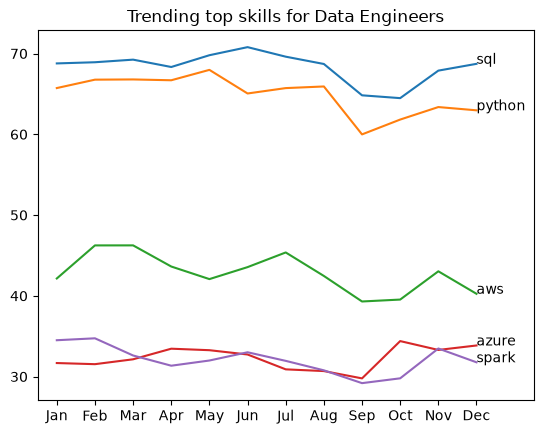

In [ ]:
df_plot = df_de_usa_percentage.iloc[:, :5]
fig, ax = plt.subplots()

for skill in df_plot.columns:
    ax.plot(df_plot.index, df_plot[skill], label=skill)

    ax.text(
        df_plot.index[-1],
        df_plot[skill].iloc[-1],
        skill
    )
plt.title('Trending top skills for Data Engineers')
ax.set_xlim(-0.5, len(df_plot.index) + 0.5)
ax.legend().remove()